In [4]:
import geopandas as gpd

# Carregar arquivo de dados geográficos
gdf = gpd.read_file("geojs-50-mun.json")

# Visualizar estrutura da tabela (primeiras 5 linhas)
print(gdf.head())

# Inspecionar os nomes das colunas disponíveis
print(gdf.columns)

# Verificar o Sistema de Referência de Coordenadas (CRS)
print(gdf.crs)

        id          name   description  \
0  5000203    Água Clara    Água Clara   
1  5000252   Alcinópolis   Alcinópolis   
2  5000609       Amambai       Amambai   
3  5000708     Anastácio     Anastácio   
4  5000807  Anaurilândia  Anaurilândia   

                                            geometry  
0  POLYGON ((-53.27086 -19.13989, -53.23275 -19.1...  
1  POLYGON ((-53.88495 -17.91284, -53.87645 -17.9...  
2  POLYGON ((-54.80106 -22.87475, -54.80334 -22.8...  
3  POLYGON ((-55.83284 -20.46006, -55.82715 -20.4...  
4  POLYGON ((-52.62136 -21.87627, -52.60972 -21.8...  
Index(['id', 'name', 'description', 'geometry'], dtype='object')
EPSG:4326


In [3]:
from google.colab import files

# Isso abrirá uma janela para você selecionar e enviar o arquivo 'geojs-50-mun.json'
uploaded = files.upload()

Saving geojs-50-mun.json to geojs-50-mun.json


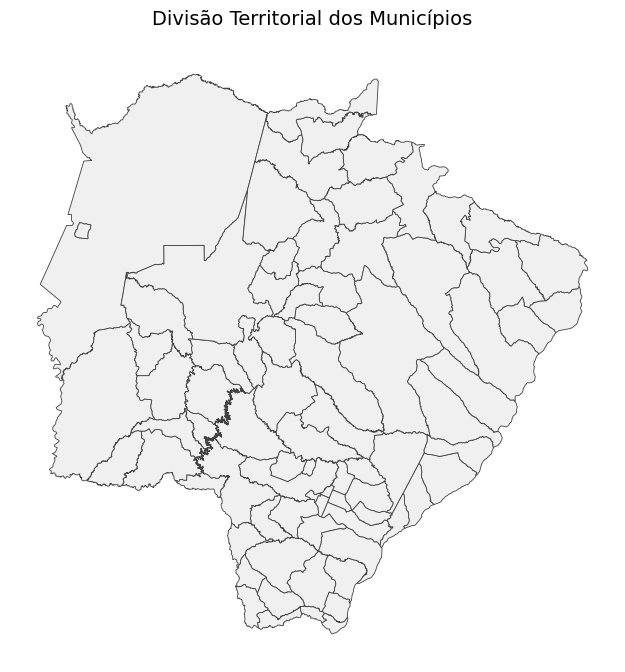

In [5]:
import matplotlib.pyplot as plt

# 1. Instanciar figura e eixos
fig, ax = plt.subplots(figsize=(10, 8))

# 2. Desenhar as geometrias contidas na coluna 'geometry'
gdf.plot(
    ax=ax,
    color="#F0F0F0",      # Cor do preenchimento interno
    edgecolor="#404040",  # Cor das linhas de borda/fronteira
    linewidth=0.6         # Espessura das linhas
)

# 3. Ajustes de apresentação
ax.set_title("Divisão Territorial dos Municípios", fontsize=14, pad=15)
ax.axis("off")  # Oculta os eixos X e Y de latitude/longitude

# 4. Renderizar a tela
plt.show()

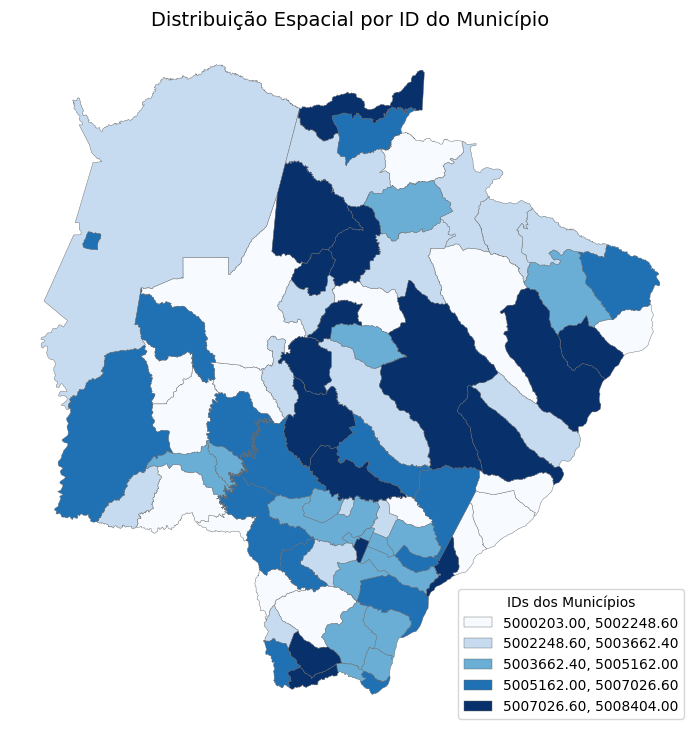

In [9]:
import pandas as pd

# Converter a coluna 'id' para numérico para que o esquema de quantis funcione
gdf['id'] = pd.to_numeric(gdf['id'])

fig, ax = plt.subplots(figsize=(12, 9))

gdf.plot(
    column='id',
    cmap='Blues',            # Paleta de cores
    scheme='Quantiles',      # Método de classificação estatística
    k=5,                     # Quantidade de classes
    legend=True,             # Exibir legenda
    legend_kwds={'loc': 'lower right', 'title': 'IDs dos Municípios'},
    ax=ax,
    edgecolor='#666666',
    linewidth=0.3
)

ax.set_title("Distribuição Espacial por ID do Município", fontsize=14)
ax.axis("off")

# Exportar a visualização para um arquivo de imagem em alta resolução
plt.savefig("mapa_final.png", dpi=300, bbox_inches='tight')
plt.show()

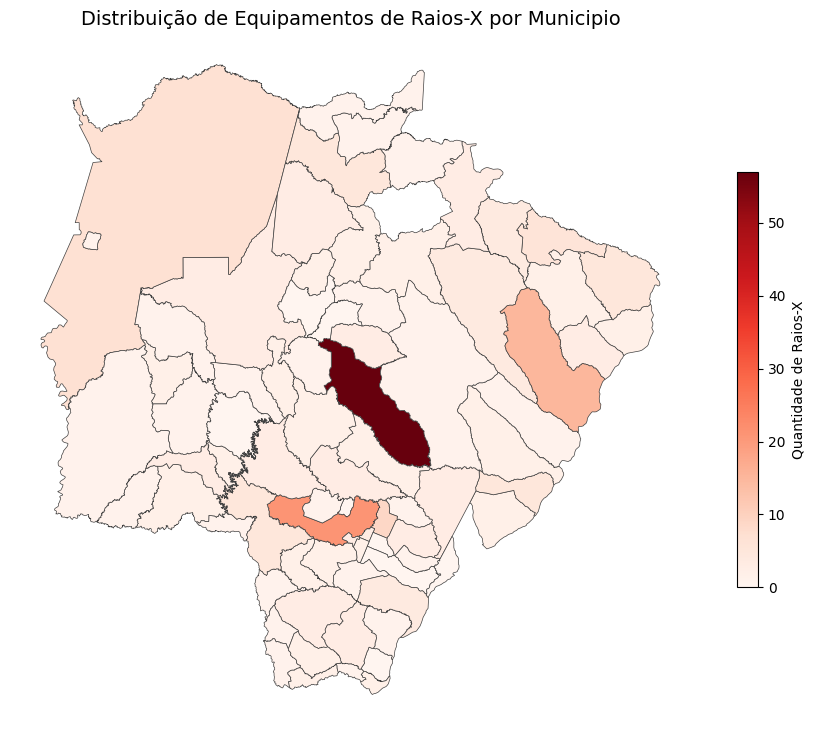

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Carregar os dados numéricos do Excel definindo a linha correta como cabeçalho (header=1)
df_dados = pd.read_excel('Excel.xlsx', header=1)

# Limpar linhas nulas se houverem no Excel
df_dados = df_dados.dropna(subset=['Municipio'])

# Padronizar os nomes para correspondência correta (ex: de 'AGUA CLARA' para 'Água Clara' se necessário)
gdf['name_clean'] = gdf['name'].str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8').str.upper()
df_dados['Municipio_clean'] = df_dados['Municipio'].astype(str).str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8').str.upper()

# 2. Unir a tabela de dados ao GeoDataFrame usando as colunas padronizadas
gdf_merged = gdf.merge(df_dados, left_on='name_clean', right_on='Municipio_clean')

# Converter a coluna de valores para numérico para plotar corretamente
gdf_merged['Quantidade'] = pd.to_numeric(gdf_merged['Quantidade'], errors='coerce')

# 3. Gerar o mapa usando a coluna de quantidade
fig, ax = plt.subplots(figsize=(12, 9))
gdf_merged.plot(
    column='Quantidade',
    cmap='Reds',
    legend=True,
    legend_kwds={'label': 'Quantidade de Raios-X', 'shrink': 0.6}, # Corrigido: usando 'label' em vez de 'loc'/'title'
    ax=ax,
    edgecolor='#404040',
    linewidth=0.5
)

ax.set_title("Distribuição de Equipamentos de Raios-X por Municipio", fontsize=14)
ax.axis("off")
plt.show()

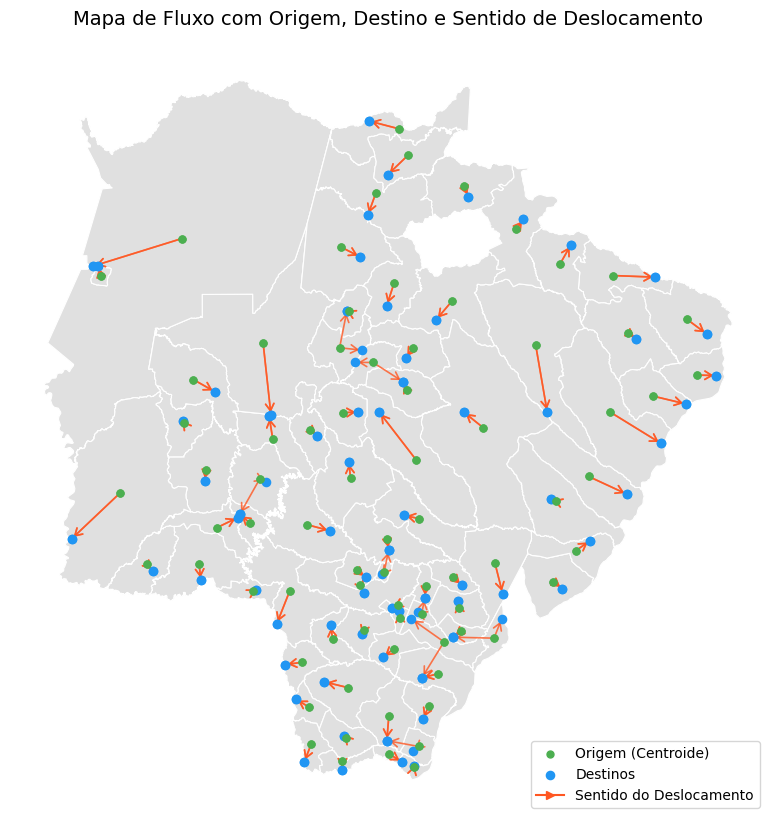

In [17]:
import unicodedata
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely.geometry as sg

# 1. Função para remover acentos e padronizar textos para o Merge
def normalizar_texto(texto):
    if not isinstance(texto, str):
        return ""
    nfkd = unicodedata.normalize('NFD', texto)
    sem_acento = "".join([c for c in nfkd if unicodedata.category(c) != 'Mn'])
    return sem_acento.strip().upper()

# 2. Carregar os dados (ajustando o cabeçalho correto com header=1)
gdf = gpd.read_file("geojs-50-mun.json")
df_excel = pd.read_excel("Excel.xlsx", header=1)

# Limpeza e padronização das chaves de junção
gdf['mun_clean'] = gdf['name'].apply(normalizar_texto)

# Trata linhas mescladas no Excel (se houver) e normaliza a coluna do município
df_excel['Municipio'] = df_excel['Municipio'].ffill()
df_excel['mun_clean'] = df_excel['Municipio'].apply(normalizar_texto)

# Conversão de coordenadas para numérico
df_excel['Latitude'] = pd.to_numeric(df_excel['Latitude'], errors='coerce')
df_excel['Longitude'] = pd.to_numeric(df_excel['Longitude'], errors='coerce')

# 3. Realizar o Merge dos dados geográficos com a planilha
gdf_merged = gdf.merge(df_excel, on='mun_clean', how='inner')

# 4. Obter centroides em sistema projetado (UTM fuso 21S / EPSG:31982) e converter de volta
centroides_utm = gdf_merged.to_crs(epsg=31982).geometry.centroid
centroides_geo = centroides_utm.to_crs(gdf_merged.crs)

gdf_merged['origem_lon'] = centroides_geo.x
gdf_merged['origem_lat'] = centroides_geo.y

# 5. Renderização do Mapa
fig, ax = plt.subplots(figsize=(12, 10))

# Desenhar mapa base dos municípios
gdf_merged.plot(ax=ax, color='#E0E0E0', edgecolor='#FFFFFF', linewidth=0.8)

# Desenhar setas de deslocamento (Origem -> Destino)
for idx, row in gdf_merged.iterrows():
    if (
        pd.notna(row['origem_lon'])
        and pd.notna(row['origem_lat'])
        and pd.notna(row['Longitude'])
        and pd.notna(row['Latitude'])
    ):
        origem = (row['origem_lon'], row['origem_lat'])
        destino = (row['Longitude'], row['Latitude'])

        # Plota a seta apenas se origem e destino forem pontos distintos
        if origem != destino:
            ax.annotate(
                "",
                xy=destino,
                xytext=origem,
                arrowprops=dict(
                    arrowstyle="->,head_width=0.3,head_length=0.5",
                    color='#FF5722',
                    lw=1.2,
                    alpha=0.8,
                ),
            )

# Marcadores gráficos
ax.scatter(
    gdf_merged['origem_lon'],
    gdf_merged['origem_lat'],
    color='#4CAF50',
    s=25,
    zorder=6,
    label='Origem (Centroide)',
)
ax.scatter(
    gdf_merged['Longitude'],
    gdf_merged['Latitude'],
    color='#2196F3',
    s=35,
    zorder=5,
    label='Destinos',
)

# Legenda customizada para as setas
ax.plot(
    [],
    [],
    color='#FF5722',
    marker='>',
    linestyle='-',
    label='Sentido do Deslocamento',
)

ax.set_title(
    "Mapa de Fluxo com Origem, Destino e Sentido de Deslocamento",
    fontsize=14,
    pad=15,
)
ax.axis("off")
plt.legend(loc='lower right')

# Exportação do mapa
plt.savefig("mapa_fluxo_final.png", dpi=300, bbox_inches='tight')
plt.show()

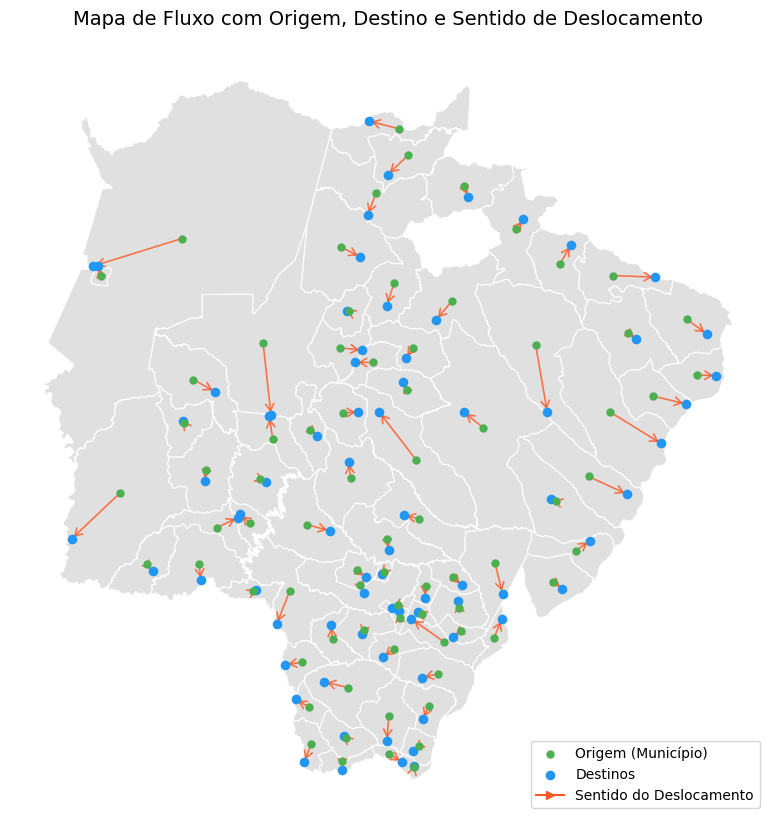

In [15]:
import shapely.geometry as sg
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Obter o centroide de forma precisa reprojetando temporariamente para UTM (EPSG:31982)
centroides_projetados = gdf_merged.to_crs(epsg=31982).geometry.centroid
centroides_geograficos = centroides_projetados.to_crs(gdf_merged.crs)

gdf_merged['centroide'] = centroides_geograficos
gdf_merged['origem_lon'] = gdf_merged['centroide'].x
gdf_merged['origem_lat'] = gdf_merged['centroide'].y

# 2. Plotar o mapa base
fig, ax = plt.subplots(figsize=(12, 10))

# Mapa base cinza de fundo
gdf_merged.plot(ax=ax, color='#E0E0E0', edgecolor='#FFFFFF', linewidth=0.8)

# 3. Desenhar as linhas com setas de direção (Origem -> Destino)
for idx, row in gdf_merged.iterrows():
    if pd.notna(row['origem_lon']) and pd.notna(row['origem_lat']) and pd.notna(row['Longitude']) and pd.notna(row['Latitude']):
        origem = (row['origem_lon'], row['origem_lat'])
        destino = (row['Longitude'], row['Latitude'])

        # Desenha a seta apontando da origem para o destino
        ax.annotate(
            "",
            xy=destino,          # Ponta da seta (Destino)
            xytext=origem,       # Base da seta (Origem)
            arrowprops=dict(
                arrowstyle="->,head_width=0.3,head_length=0.5",
                color='#FF5722',
                lw=1.2,
                alpha=0.8
            )
        )

# 4. Desenhar os marcadores de ORIGEM (Centroides dos municípios em verde)
ax.scatter(gdf_merged['origem_lon'], gdf_merged['origem_lat'], color='#4CAF50', s=25, zorder=6, label='Origem (Município)')

# 5. Desenhar os marcadores de DESTINO (Pontos da planilha em azul)
ax.scatter(gdf_merged['Longitude'], gdf_merged['Latitude'], color='#2196F3', s=35, zorder=5, label='Destinos')

# Elemento artificial para criar a legenda da seta
ax.plot([], [], color='#FF5722', marker='>', linestyle='-', label='Sentido do Deslocamento')

ax.set_title("Mapa de Fluxo com Origem, Destino e Sentido de Deslocamento", fontsize=14, pad=15)
ax.axis("off")
plt.legend(loc='lower right')
plt.show()